In [1]:
import data_loaders
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
data = data_loaders.DataLoader()

                       date  Day-ahead price (EUR/MWh)
0 2015-01-01 00:00:00+00:00                      27.07
1 2015-01-01 01:00:00+00:00                      26.93
2 2015-01-01 02:00:00+00:00                      26.83
3 2015-01-01 03:00:00+00:00                      26.81
4 2015-01-01 04:00:00+00:00                      26.97 

       Day-ahead price (EUR/MWh)
count              103062.000000
mean                   59.492173
std                    67.356150
min                   -61.840000
25%                    25.360000
50%                    40.770000
75%                    69.080000
max                   898.250000 

Dupl/Null 0 , 0


<Axes: xlabel='date'>

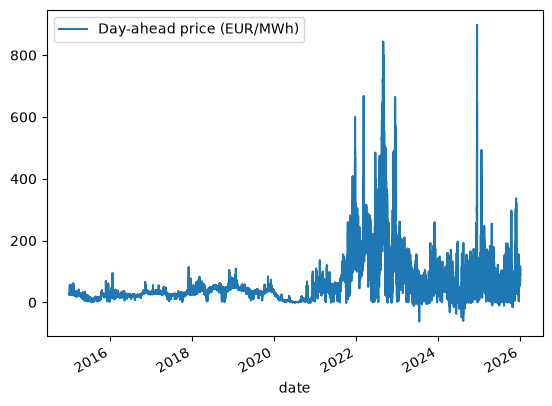

In [3]:
# MARKET PRICE
d = data.day_ahead_price_data.copy()
print(d.head(), '\n')
print(d.describe(), '\n')
print(f'Dupl/Null {d.isnull().sum().sum()} , {d.duplicated().sum()}')

d.plot(x='date', y='Day-ahead price (EUR/MWh)')

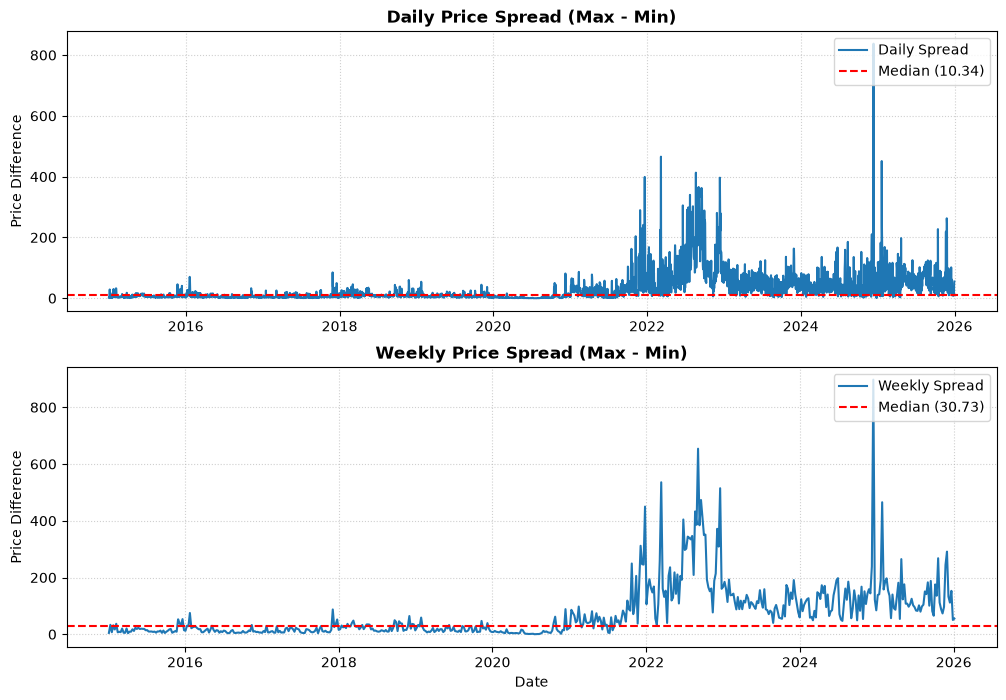

In [4]:
if 'date' in d.columns:
    d = d.set_index('date')
price_col = [col for col in d.columns if col != 'date'][0]

daily_spread = d[price_col].resample('D').apply(lambda x: x.max() - x.min()).dropna()
weekly_spread = d[price_col].resample('W').apply(lambda x: x.max() - x.min()).dropna()
median_daily = daily_spread.median()
median_weekly = weekly_spread.median()

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharey=False)
axes[0].plot(daily_spread.index, daily_spread.values, label='Daily Spread')
axes[0].axhline(median_daily, color='red', linestyle='--', linewidth=1.5, label=f'Median ({median_daily:.2f})')
axes[0].set_title('Daily Price Spread (Max - Min)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Price Difference')
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend(loc='upper right')

axes[1].plot(weekly_spread.index, weekly_spread.values, label='Weekly Spread')
axes[1].axhline(median_weekly, color='red', linestyle='--', linewidth=1.5, label=f'Median ({median_weekly:.2f})')
axes[1].set_title('Weekly Price Spread (Max - Min)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Price Difference')
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend(loc='upper right')

plt.show()

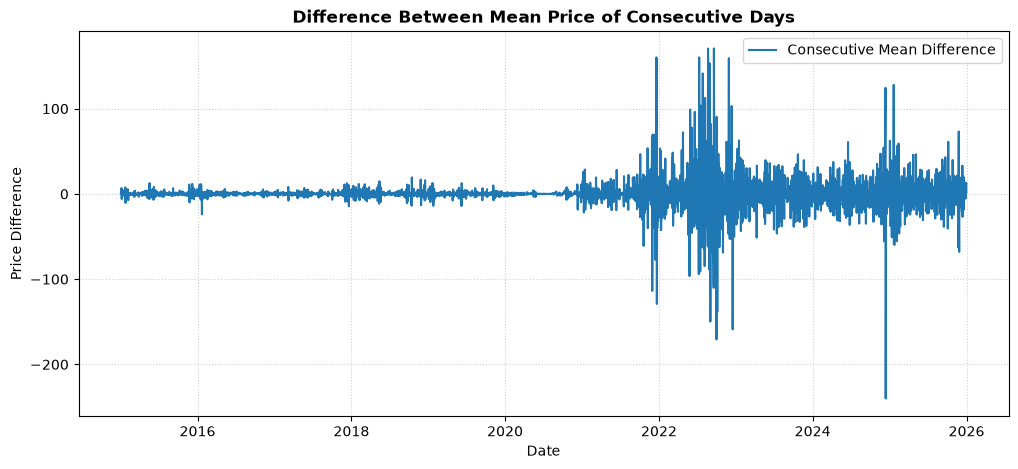

In [5]:
daily_mean = d[price_col].resample('D').mean()
daily_mean_diff = daily_mean.diff().dropna()
median_diff = daily_mean_diff.median()
median_abs_diff = daily_mean_diff.abs().median()

plt.figure(figsize=(12, 5))
plt.plot(
    daily_mean_diff.index, 
    daily_mean_diff.values, 
    label='Consecutive Mean Difference'
)

plt.title('Difference Between Mean Price of Consecutive Days', fontsize=12, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Price Difference')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()

In [6]:
# INFLOW
d2 = data.inflow_data.copy()
print(d2.head(), '\n')
print(d2.describe(), '\n')
print(f'Dupl/Null {d2.isnull().sum().sum()} , {d2.duplicated().sum()}')

                       date  Langesae  Staavatn  Kjelavatn  Bordalsvatn  \
0 1958-01-01 00:00:00+00:00      0.37      0.03       1.23          0.5   
1 1958-01-01 01:00:00+00:00      0.37      0.03       1.23          0.5   
2 1958-01-01 02:00:00+00:00      0.37      0.03       1.23          0.5   
3 1958-01-01 03:00:00+00:00      0.37      0.03       1.23          0.5   
4 1958-01-01 04:00:00+00:00      0.37      0.03       1.23          0.5   

   Foersvatn  Hyljelihyl  Venemo  Bitdalsvatn  Songavatn  Totak  Vaamarvatn  \
0       0.05        0.34    0.37         1.07       4.92   3.28        0.21   
1       0.05        0.34    0.37         1.07       4.92   3.28        0.21   
2       0.05        0.34    0.37         1.07       4.92   3.28        0.21   
3       0.05        0.34    0.37         1.07       4.92   3.28        0.21   
4       0.05        0.34    0.37         1.07       4.92   3.28        0.21   

   Langeidvatn  Vatjern  Vinjevatn  Botnedalsvatn  Byrtevatn  Bandak  \
0 

In [7]:
# if 'date' in d2.columns:
#     d2 = d2.set_index('date')

# reservoir_cols = d2.columns
# num_reservoirs = len(reservoir_cols)

#
# fig, axes = plt.subplots(
#     nrows=num_reservoirs, 
#     ncols=1, 
#     figsize=(12, 3 * num_reservoirs), 
#     sharex=True
# )

#
# colors = plt.cm.tab10.colors  # Cycle through standard plot colors

# for i, col in enumerate(reservoir_cols):
#     ax = axes[i]
#     ax.plot(d.index, d[col], label=col, color=colors[i % len(colors)], linewidth=1)
#     ax.set_title(f'Reservoir: {col}', fontsize=11, fontweight='bold', loc='left')
#     ax.set_ylabel('Inflow')
#     ax.grid(True, linestyle=':', alpha=0.6)
#     ax.legend(loc='upper right')

# axes[-1].set_xlabel('Date')

# plt.tight_layout()
# plt.show()

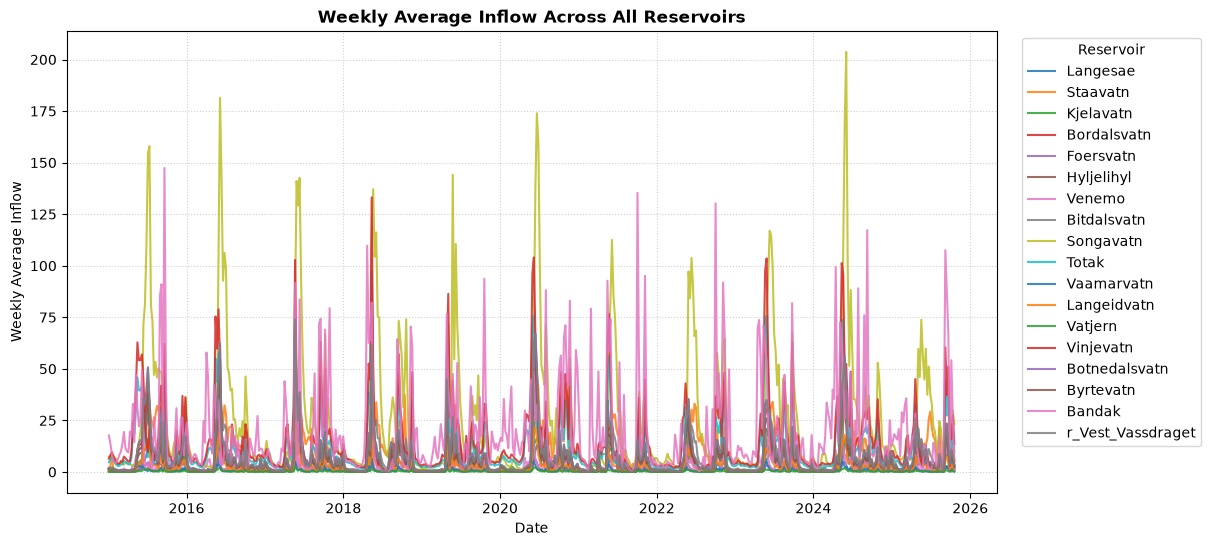

In [8]:
if 'date' in d2.columns:
    d2 = d2.set_index('date')
d2 = d2.loc['2015-01-01':]

weekly_inflow = d2.resample('W').mean()

plt.figure(figsize=(12, 6))

for column in weekly_inflow.columns:
    plt.plot(
        weekly_inflow.index, 
        weekly_inflow[column], 
        label=column, 
        alpha=0.85, 
        linewidth=1.5
    )

plt.title('Weekly Average Inflow Across All Reservoirs', fontsize=12, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Weekly Average Inflow')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(title='Reservoir', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

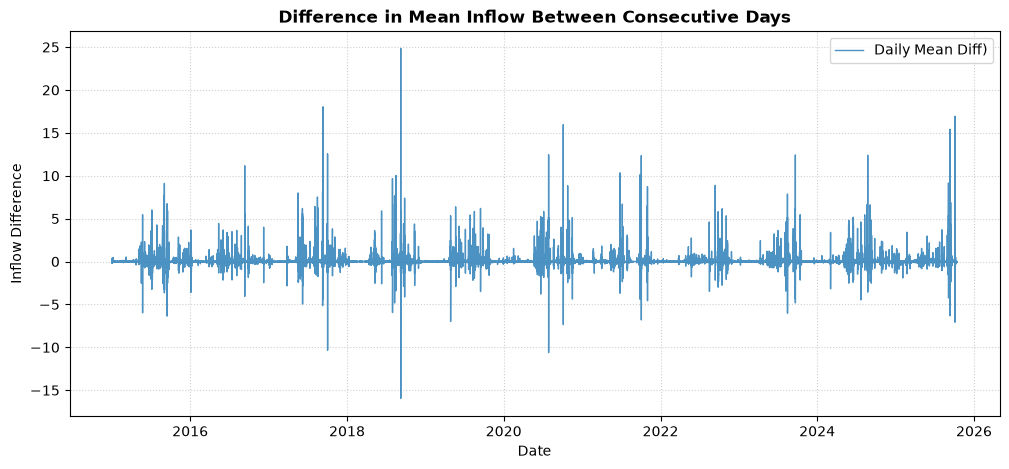

In [9]:
daily_mean = d2.mean(axis=1)
daily_mean_diff = daily_mean.diff().dropna()

plt.figure(figsize=(12, 5))
plt.plot(
    daily_mean_diff.index, 
    daily_mean_diff.values, 
    alpha=0.8, 
    linewidth=1, 
    label='Daily Mean Diff)'
)

plt.title('Difference in Mean Inflow Between Consecutive Days', fontsize=12, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Inflow Difference')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right')
plt.show()

In [10]:
# RESERVOIR STORAGE
d3 = data.volume_data.copy()
print(d3.head(), '\n')
print(d3.describe(), '\n')
print(f'Dupl/Null {d3.isnull().sum().sum()} , {d3.duplicated().sum()}')

                       date  Kjelavatn  Staavatn  Langesae  Foersvatn  Venemo  \
0 2015-01-01 00:00:00+00:00     42.352    17.472    56.669     92.150  18.263   
1 2015-01-02 00:00:00+00:00     42.001    16.474    56.262     92.185  18.332   
2 2015-01-03 00:00:00+00:00     41.494    15.360    55.753     92.079  18.356   
3 2015-01-04 00:00:00+00:00     41.221    14.784    55.516     91.938  18.388   
4 2015-01-05 00:00:00+00:00     41.182    14.630    55.482     91.903  18.388   

   Botnedalsvatn  Bitdalsvatn  Vaamarvatn  Langeidvatn    Totak  Songavatn  \
0         32.999       92.404       9.796       30.541  170.219    492.379   
1         32.999       92.024      11.079       30.587  170.219    489.891   
2         32.743       91.786      12.257       30.587  170.219    487.126   
3         32.589       91.453      11.425       30.541  169.512    485.468   
4         32.538       91.025      10.143       30.541  169.512    485.191   

   Vinjevatn   Bandak  Bordalsvatn  Byrtevat

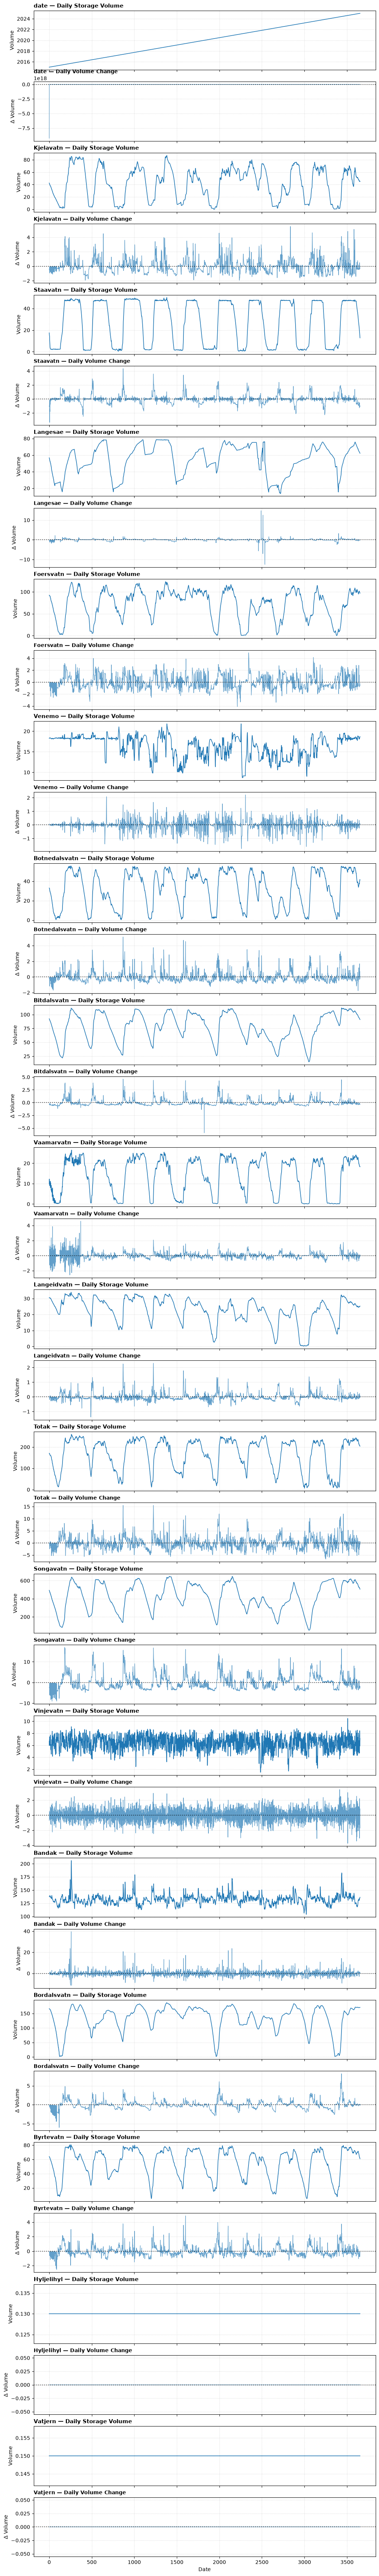

In [11]:
d3_diff = d3.diff()
reservoir_cols = d3.columns
num_reservoirs = len(reservoir_cols)

fig, axes = plt.subplots(
    nrows=num_reservoirs * 2, 
    ncols=1, 
    figsize=(12, 2.5 * num_reservoirs * 2), 
    sharex=True
)

for i, col in enumerate(reservoir_cols):
    ax_vol = axes[2 * i]
    ax_diff = axes[2 * i + 1]
    
    ax_vol.plot(d3.index, d3[col], label=f'{col} Volume', linewidth=1.2)
    ax_vol.set_title(f'{col} — Daily Storage Volume', fontsize=11, fontweight='bold', loc='left')
    ax_vol.set_ylabel('Volume')
    ax_vol.grid(True, linestyle=':', alpha=0.6)
    
    ax_diff.plot(d3_diff.index, d3_diff[col], label=f'{col} Change', alpha=0.7, linewidth=0.9)
    ax_diff.axhline(0, color='black', linestyle=':', alpha=0.7)
    ax_diff.set_title(f'{col} — Daily Volume Change', fontsize=10, fontweight='bold', loc='left')
    ax_diff.set_ylabel('$\Delta$ Volume')
    ax_diff.grid(True, linestyle=':', alpha=0.6)
axes[-1].set_xlabel('Date')
plt.show()

In [19]:
for df in (d2, d3):
    if 'date' in df.columns:
        df.set_index('date', inplace=True)
    if not isinstance(df.index, pd.DatetimeIndex):
        df.index = pd.to_datetime(df.index)

common_reservoirs = d2.columns.intersection(d3.columns)

correlations = {}
for reservoir in common_reservoirs:
    corr = d2[reservoir].corr(d3[reservoir])
    correlations[reservoir] = corr

corr_df = pd.DataFrame(
    list(correlations.items()), 
    columns=['Reservoir', 'Inflow vs Volume Correlation']
).sort_values(by='Inflow vs Volume Correlation', ascending=False)

print("Correlation between Inflow and Storage Volume:\n")
print(corr_df.to_string(index=False))

cross_corr = d2.corrwith(d3, axis=0) # Direct matching columns

# Or compute full matrix between all pairs:
full_matrix = pd.DataFrame(
    index=d2.columns, 
    columns=d3.columns,
    data=[[d2[col1].corr(d3[col2]) for col2 in d3.columns] for col1 in d2.columns]
)

print("\nFull Cross-Correlation Matrix (Rows: Inflow, Columns: Volume):")
print(full_matrix)

Correlation between Inflow and Storage Volume:

    Reservoir  Inflow vs Volume Correlation
     Staavatn                  5.431049e-01
       Bandak                  3.907761e-01
  Langeidvatn                  1.642643e-01
Botnedalsvatn                  1.528327e-01
    Byrtevatn                  1.470129e-01
    Kjelavatn                  1.188121e-01
  Bitdalsvatn                  6.922954e-02
     Langesae                  5.999450e-02
    Vinjevatn                  2.067817e-02
       Venemo                  9.638776e-03
      Vatjern                  1.684053e-17
   Hyljelihyl                  1.076832e-18
    Songavatn                 -4.029582e-04
   Vaamarvatn                 -6.133865e-02
        Totak                 -6.264781e-02
    Foersvatn                 -2.000638e-01
  Bordalsvatn                 -2.465314e-01

Full Cross-Correlation Matrix (Rows: Inflow, Columns: Volume):
                   Kjelavatn  Staavatn  Langesae  Foersvatn    Venemo  \
Langesae            0.0

In [13]:
# RESERVOIR WATER VALUE
d4 = data.volume_data.copy()
print(d4.head(), '\n')
print(d4.describe(), '\n')
print(f'Dupl/Null {d4.isnull().sum().sum()} , {d4.duplicated().sum()}')

                       date  Kjelavatn  Staavatn  Langesae  Foersvatn  Venemo  \
0 2015-01-01 00:00:00+00:00     42.352    17.472    56.669     92.150  18.263   
1 2015-01-02 00:00:00+00:00     42.001    16.474    56.262     92.185  18.332   
2 2015-01-03 00:00:00+00:00     41.494    15.360    55.753     92.079  18.356   
3 2015-01-04 00:00:00+00:00     41.221    14.784    55.516     91.938  18.388   
4 2015-01-05 00:00:00+00:00     41.182    14.630    55.482     91.903  18.388   

   Botnedalsvatn  Bitdalsvatn  Vaamarvatn  Langeidvatn    Totak  Songavatn  \
0         32.999       92.404       9.796       30.541  170.219    492.379   
1         32.999       92.024      11.079       30.587  170.219    489.891   
2         32.743       91.786      12.257       30.587  170.219    487.126   
3         32.589       91.453      11.425       30.541  169.512    485.468   
4         32.538       91.025      10.143       30.541  169.512    485.191   

   Vinjevatn   Bandak  Bordalsvatn  Byrtevat

In [14]:
for df in (d3, d4):
    if 'date' in df.columns:
        df.set_index('date', inplace=True)
    if not isinstance(df.index, pd.DatetimeIndex):
        df.index = pd.to_datetime(df.index)
common_reservoirs = d3.columns.intersection(d4.columns)

correlations = {}
for reservoir in common_reservoirs:
    corr = d3[reservoir].corr(d4[reservoir])
    correlations[reservoir] = corr

wv_corr_df = pd.DataFrame(
    list(correlations.items()), 
    columns=['Reservoir', 'Volume vs Water Value Correlation']
).sort_values(by='Volume vs Water Value Correlation')

print("Correlation between Storage Volume and Synthetic Water Value\n")
print(wv_corr_df.to_string(index=False))

Correlation between Storage Volume and Synthetic Water Value

    Reservoir  Volume vs Water Value Correlation
    Foersvatn                                1.0
   Hyljelihyl                                1.0
      Vatjern                                1.0
     Staavatn                                1.0
       Venemo                                1.0
Botnedalsvatn                                1.0
  Bitdalsvatn                                1.0
    Kjelavatn                                1.0
   Vaamarvatn                                1.0
  Langeidvatn                                1.0
    Songavatn                                1.0
        Totak                                1.0
    Vinjevatn                                1.0
       Bandak                                1.0
  Bordalsvatn                                1.0
     Langesae                                1.0
    Byrtevatn                                1.0


In [15]:
price_col = [col for col in d.columns if col != 'date'][0]
daily_price = d[price_col].resample('D').mean()

correlations = {}
for reservoir in d4.columns:
    corr = d4[reservoir].corr(daily_price)
    correlations[reservoir] = corr

price_wv_corr_df = pd.DataFrame(
    list(correlations.items()), 
    columns=['Reservoir', 'Water Value vs Daily Price Correlation']
).sort_values(by='Water Value vs Daily Price Correlation', ascending=False)

print("Correlation between Water Value and Daily Price:\n")
print(price_wv_corr_df.to_string(index=False))

Correlation between Water Value and Daily Price:

    Reservoir  Water Value vs Daily Price Correlation
  Bordalsvatn                            4.569714e-02
      Vatjern                           -3.412301e-17
   Hyljelihyl                           -3.412301e-17
   Vaamarvatn                           -5.323869e-03
        Totak                           -8.172540e-03
     Staavatn                           -1.671266e-02
    Foersvatn                           -1.801815e-02
    Byrtevatn                           -5.602822e-02
       Bandak                           -6.400712e-02
    Kjelavatn                           -7.706798e-02
    Vinjevatn                           -1.030698e-01
    Songavatn                           -1.716728e-01
Botnedalsvatn                           -2.226232e-01
  Bitdalsvatn                           -2.304660e-01
  Langeidvatn                           -2.781855e-01
     Langesae                           -2.859879e-01
       Venemo                   

In [16]:
# Reservoir minimum volume
d5 = data.min_flow_constraint_data.copy()
print(d5.head(), '\n')
print(d5.describe(), '\n')
print(f'Dupl/Null {d5.isnull().sum().sum()} , {d5.duplicated().sum()}')

                       date  b_Kjelavatn  b_Hyljelihyl  b_Vinjevatn  \
0 2015-01-01 00:00:00+00:00          0.3           0.5          1.0   
1 2015-01-01 01:00:00+00:00          0.3           0.5          1.0   
2 2015-01-01 02:00:00+00:00          0.3           0.5          1.0   
3 2015-01-01 03:00:00+00:00          0.3           0.5          1.0   
4 2015-01-01 04:00:00+00:00          0.3           0.5          1.0   

   b_Byrtevatn  b_Bandak  r_Vest_Vassdraget  
0          0.0       4.0                5.0  
1          0.0       4.0                5.0  
2          0.0       4.0                5.0  
3          0.0       4.0                5.0  
4          0.0       4.0                5.0   

        b_Kjelavatn  b_Hyljelihyl   b_Vinjevatn   b_Byrtevatn      b_Bandak  \
count  96432.000000  96432.000000  96432.000000  96432.000000  96432.000000   
mean       0.469353      1.064647      1.418865      0.067894      4.418865   
std        0.211576      0.705255      0.493376      0.094

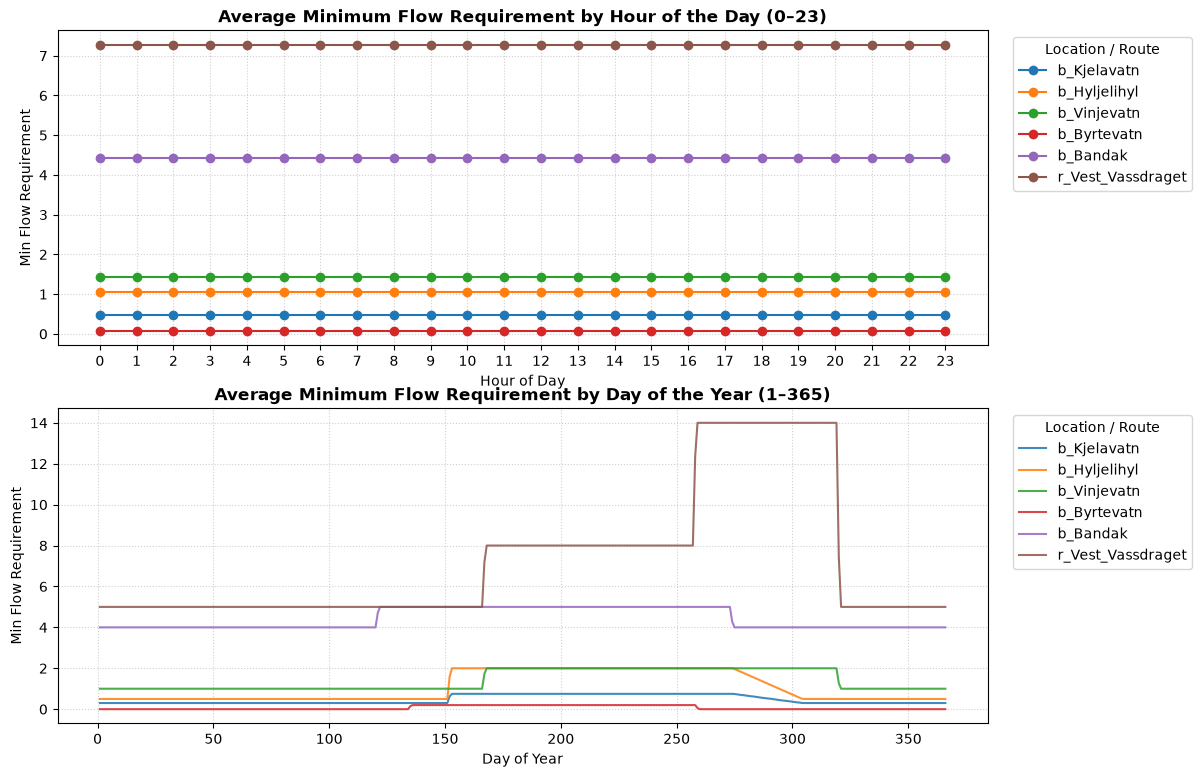

In [17]:
if 'date' in d5.columns:
    d5.set_index('date', inplace=True)
if not isinstance(d5.index, pd.DatetimeIndex):
    d5.index = pd.to_datetime(d5.index)

flow_cols = d5.columns
fig, axes = plt.subplots(2, 1, figsize=(12, 9))

d5_hourly = d5.groupby(d5.index.hour).mean()

for col in flow_cols:
    axes[0].plot(d5_hourly.index, d5_hourly[col], marker='o', label=col, linewidth=1.5)

axes[0].set_title('Average Minimum Flow Requirement by Hour of the Day (0–23)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Hour of Day')
axes[0].set_ylabel('Min Flow Requirement')
axes[0].set_xticks(range(0, 24))
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend(title='Location / Route', bbox_to_anchor=(1.02, 1), loc='upper left')

d5_daily = d5.groupby(d5.index.dayofyear).mean()

for col in flow_cols:
    axes[1].plot(d5_daily.index, d5_daily[col], label=col, linewidth=1.5, alpha=0.85)

axes[1].set_title('Average Minimum Flow Requirement by Day of the Year (1–365)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Day of Year')
axes[1].set_ylabel('Min Flow Requirement')
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend(title='Location / Route', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

NameError: name 'mdates' is not defined

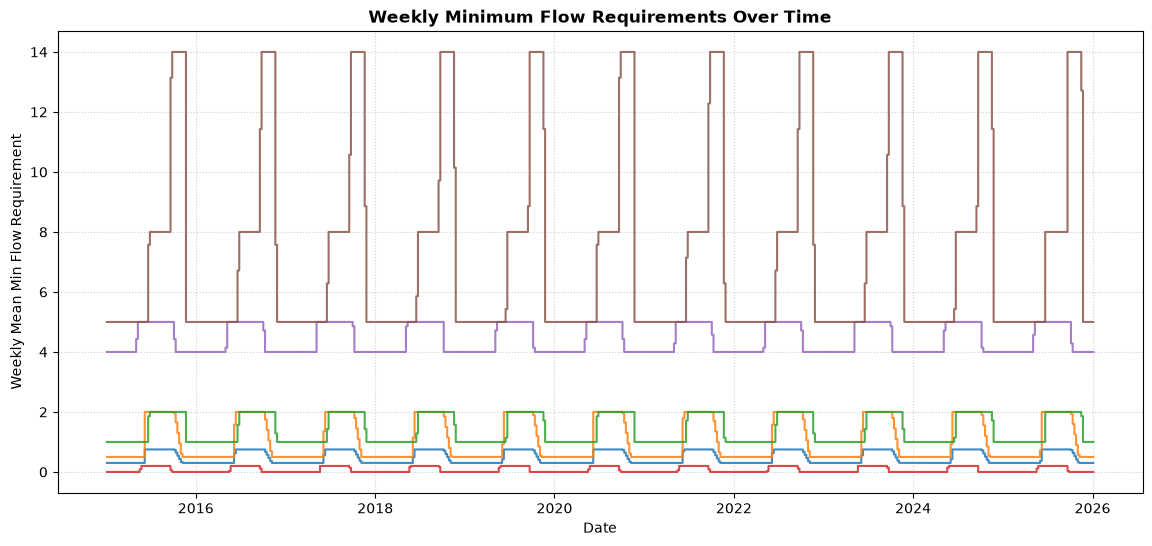

In [18]:
d5_weekly = d5.resample('W').mean()

plt.figure(figsize=(14, 6))

for col in d5_weekly.columns:
    plt.plot(
        d5_weekly.index, 
        d5_weekly[col], 
        label=col, 
        alpha=0.85, 
        linewidth=1.5,
        drawstyle='steps-post'
    )

plt.title('Weekly Minimum Flow Requirements Over Time', fontsize=12, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Weekly Mean Min Flow Requirement')
plt.grid(True, linestyle=':', alpha=0.6)

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=45)
plt.legend(title='Location / Route', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

In [ ]:
# RESERVOIR MINIMUM VALUE
d6 = data.min_volume_constraint_data.copy()
print(d6.head(), '\n')
print(d6.describe(), '\n')
print(f'Dupl/Null {d6.isnull().sum().sum()} , {d6.duplicated().sum()}')

In [ ]:
if 'date' in d6.columns:
    d6.set_index('date', inplace=True)
if not isinstance(d6.index, pd.DatetimeIndex):
    d6.index = pd.to_datetime(d6.index)

d6_weekly = d6.resample('W').mean()
plt.figure(figsize=(14, 6))

for col in d6_weekly.columns:
    plt.plot(
        d6_weekly.index, 
        d6_weekly[col], 
        label=col, 
        alpha=0.85, 
        linewidth=1.5,
        drawstyle='steps-post'
    )

plt.title('Weekly Minimum Storage Volume Constraints Over Time', fontsize=12, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Min Volume Constraint')
plt.grid(True, linestyle=':', alpha=0.6)

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=45)
plt.legend(title='Reservoir', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

In [ ]:
common_reservoirs = d6.columns.intersection(d2.columns)

correlations = {}
for reservoir in common_reservoirs:
    if d6[reservoir].nunique() > 1:
        corr = d6[reservoir].corr(d2[reservoir])
        correlations[reservoir] = corr
    else:
        correlations[reservoir] = None  # Constant constraint (0 std dev)

vol_constraint_corr_df = pd.DataFrame(
    [
        {
            'Reservoir': r, 
            'Min Volume Constraint vs Inflow Correlation': c if c is not None else 'Constant Constraint (NaN)'
        }
        for r, c in correlations.items()
    ]
)

print("Correlation between Minimum Volume Constraint and Inflow\n")
print(vol_constraint_corr_df.to_string(index=False))

In [ ]:
# # 4. Extract Plant name from column headers (e.g., 'result_committed_Hogga_G1_t0' -> 'Hogga')
# # Note: Format assumes 'result_committed_PLANT_UNIT_...' pattern
# def extract_plant_name(col):
#     parts = col.split('_')
#     if len(parts) >= 3 and parts[0] == 'result' and parts[1] == 'committed':
#         return parts[2]
#     return col

# # Map commitment columns to their respective plants
# plant_commitment_cols = {col: extract_plant_name(col) for col in d7.columns}

# # 5. Calculate pairwise correlations between unit status and minimum storage constraints
# results = []

# # Loop over each unit commitment decision column
# for unit_col, plant in plant_commitment_cols.items():
#     # Find matching or related reservoir in d6
#     # (Matches exact plant/reservoir name if column exists in d6)
#     matching_reservoirs = [res for res in d6.columns if plant.lower() in res.lower()]
    
#     if not matching_reservoirs:
#         # If no direct substring match, evaluate against all reservoirs in d6
#         matching_reservoirs = d6.columns

#     for res in matching_reservoirs:
#         # Skip if minimum constraint has zero variance (constant series)
#         if d6[res].nunique() > 1 and d7[unit_col].nunique() > 1:
#             corr = d7[unit_col].corr(d6[res])
#         else:
#             corr = None  # Constant constraint or status yields undefined correlation
            
#         results.append({
#             'Unit Decision Variable': unit_col,
#             'Plant': plant,
#             'Reservoir Constraint': res,
#             'Correlation': corr if corr is not None else 'Constant / Zero Variance'
#         })

# # 6. Format into a clean DataFrame
# uc_corr_df = pd.DataFrame(results)

# print("Unit Commitment Decisions vs. Minimum Storage Volume Constraints (2015–Present):\n")
# print(uc_corr_df.to_string(index=False))